In [1]:
from sklearn.datasets import fetch_openml

In [2]:
mnist = fetch_openml('mnist_784', version =1, as_frame= False)

C:\Users\cvini\AppData\Roaming\Python\Python310\site-packages\sklearn\datasets\_openml.py:1022: FutureWarning: The default value of `parser` will change from `'liac-arff'` to `'auto'` in 1.4. You can set `parser='auto'` to silence this warning. Therefore, an `ImportError` will be raised from 1.4 if the dataset is dense and pandas is not installed. Note that the pandas parser may return different data types. See the Notes Section in fetch_openml's API doc for details.
  warn(


In [3]:
mnist.keys()

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

In [4]:
x, y = mnist["data"], mnist["target"]


In [5]:
x.shape

(70000, 784)

In [6]:
y.shape

(70000,)

In [7]:
%matplotlib inline

In [8]:
import matplotlib as mpl 
import matplotlib.pyplot as plt

In [9]:
some_digit = x[0]
some_digit_image = some_digit.reshape(28,28)

(-0.5, 27.5, 27.5, -0.5)

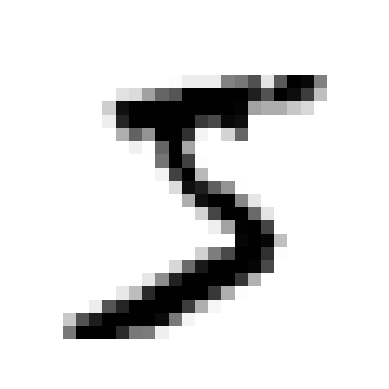

In [10]:
plt.imshow(some_digit_image, cmap = mpl.cm.binary, interpolation = "nearest")
plt.axis("off")

In [11]:
y[0]

'5'

In [12]:
import numpy as np
y = y.astype(np.int8)

In [13]:
x_train, x_test, y_train, y_test = x[:60000], x[60000:], y[:60000], y[60000:]

In [14]:
y_train_5 = (y_train==5)
y_test_5 = (y_test == 5)

In [35]:
y_train_5

array([ True, False, False, ...,  True, False, False])

In [36]:
y_test_5

array([False, False, False, ..., False,  True, False])

In [37]:
from sklearn.linear_model import SGDClassifier
sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(x_train, y_train_5)

SGDClassifier(random_state=42)

In [38]:
sgd_clf.predict([some_digit])

array([ True])

In [39]:
from sklearn.model_selection import cross_val_score
a =cross_val_score(sgd_clf, x_train, y_train_5, cv = 3, scoring="accuracy")

In [40]:
a

array([0.95035, 0.96035, 0.9604 ])

In [41]:
a.mean()

0.9570333333333334

## Not-5 Classifier

In [42]:
from sklearn.base import BaseEstimator

In [43]:
class Not5(BaseEstimator):
    def fit(self, x , y=None):
        pass
    def predict(self,x):
        return np.zeros((len(x), 1), dtype = bool)


In [44]:
never_5_clf = Not5()
b=cross_val_score(never_5_clf, x_train , y_train_5, cv = 3, scoring ="accuracy")
b

array([0.91125, 0.90855, 0.90915])

In [45]:
b.mean()

0.90965

## Confusion Matrix

In [31]:
from sklearn.model_selection import cross_val_predict
y_train_pred = cross_val_predict(sgd_clf, x_train ,y_train_5, cv=3)

In [32]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_train_5, y_train_pred)

array([[53892,   687],
       [ 1891,  3530]], dtype=int64)

In [33]:
y_train_perfect_predictions = y_train_5

## Assuming perfection

In [34]:
confusion_matrix(y_train_5, y_train_perfect_predictions)

array([[54579,     0],
       [    0,  5421]], dtype=int64)

## Precision and Recall

In [47]:
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

In [49]:
precision_score(y_train_5, y_train_pred)


0.8370879772350012

In [50]:
recall_score(y_train_5, y_train_pred)


0.6511713705958311

In [53]:
from sklearn.metrics import f1_score
f1_score(y_train_5, y_train_pred)

0.7325171197343846

In [66]:
y_scores1= sgd_clf.decision_function([some_digit])
y_scores1

array([2164.22030239])

In [67]:
threshold = 8000
y_some_digit_pred = (y_scores1 > threshold)
print (y_some_digit_pred)

[False]


In [68]:
y_scores = cross_val_predict(sgd_clf, x_train, y_train_5, cv = 3, method= "decision_function")

In [69]:
from sklearn.metrics import precision_recall_curve
precisions, recalls, thresholds = precision_recall_curve(y_train_5, y_scores)


In [74]:
def plot_precision_recall_vs_threshold(precision, recall, threshold):
    plt.plot(threshold, precisions[:-1], "b--", label = "Precision")
    plt.plot(threshold, recalls[:-1], "g-", label = "Recall")
    plt.legend()
    plt.grid()

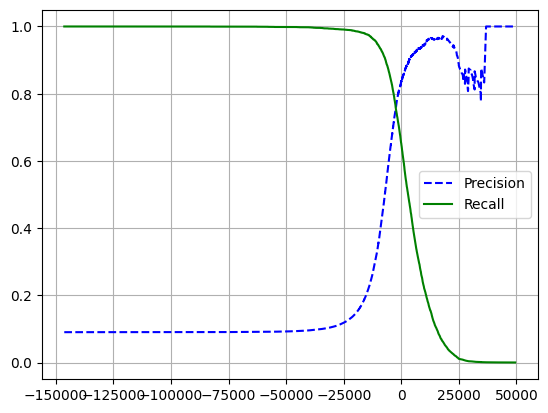

In [75]:
plot_precision_recall_vs_threshold(precisions, recalls, thresholds)
plt.show()

In [82]:
thresh_90_prec = thresholds[np.argmax(precisions >= 0.90)]
thresh_90_prec

3370.0194991439557

In [86]:
y_trained_90_prec= (y_scores >= thresh_90_prec)

In [88]:
precision_score(y_train_5, y_trained_90_prec)

0.9000345901072293

In [89]:
recall_score(y_train_5, y_trained_90_prec)

0.4799852425751706

## ROC Curve

In [90]:
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(y_train_5, y_scores)

In [102]:
def plot_roc_curve(fpr, tpr, label = None):
    plt.plot(fpr, tpr, linewidth=2,label = label)
    plt.plot([0,1],[0,1],"k--")
    plt.grid()
    plt.xlabel("FPR")
    plt.ylabel("TPR(Recall)")

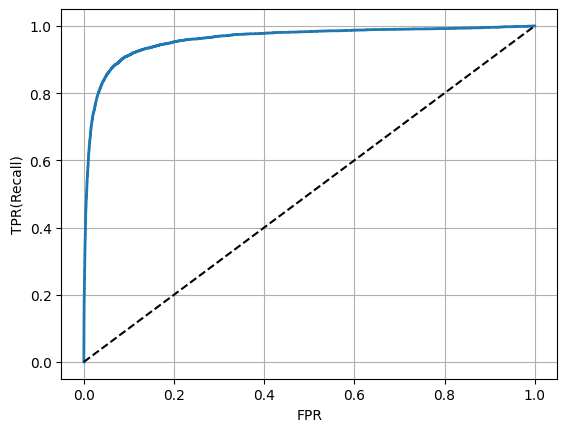

In [103]:
plot_roc_curve(fpr, tpr)
plt.show()

## ROC AUC Curve

In [104]:
from sklearn.metrics import roc_auc_score
roc_auc_score(y_train_5, y_scores)

0.9604938554008616

## RandomForestClassifier

In [105]:
from sklearn.ensemble import RandomForestClassifier
forest_clf = RandomForestClassifier(random_state=42)

In [106]:
y_proba_forest = cross_val_predict(forest_clf, x_train, y_train_5, cv = 3, method="predict_proba")

In [107]:
y_socres_forest = y_proba_forest[:,1]
fpr_forest, tpr_forest, threshold_forest = roc_curve(y_train_5, y_socres_forest)

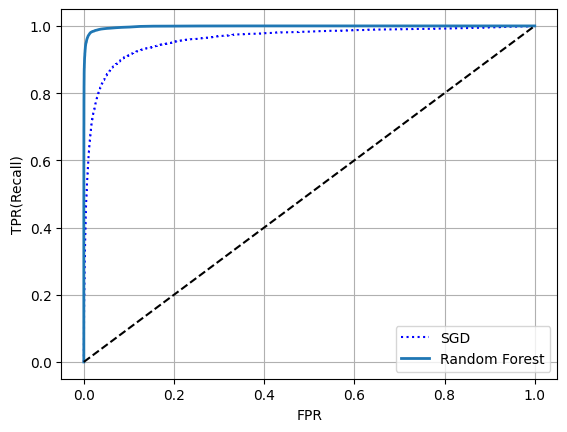

In [109]:
plt.plot(fpr,tpr,"b:", label="SGD")
plot_roc_curve(fpr_forest, tpr_forest, "Random Forest")
plt.legend(loc = "lower right")
plt.show()


In [114]:
roc_auc_score(y_train_5, y_socres_forest)

0.9983436731328145

## MultiClass Classification

In [118]:
sgd_clf.fit(x_train, y_train)
sgd_clf.predict([some_digit])

array([3], dtype=int8)

In [120]:
some_digit_score = sgd_clf.decision_function([some_digit])
some_digit_score

array([[-31893.03095419, -34419.69069632,  -9530.63950739,
          1823.73154031, -22320.14822878,  -1385.80478895,
        -26188.91070951, -16147.51323997,  -4604.35491274,
        -12050.767298  ]])

In [121]:
np.argmax(some_digit_score)

3

In [122]:
sgd_clf.classes_

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=int8)

In [123]:
sgd_clf.classes_[5]

5

In [125]:
from sklearn.multiclass import OneVsOneClassifier
ovo_clf = OneVsOneClassifier(SGDClassifier(random_state=42))

In [126]:
ovo_clf.fit(x_train, y_train)

OneVsOneClassifier(estimator=SGDClassifier(random_state=42))

In [127]:
ovo_clf.predict([some_digit])

array([5], dtype=int8)

In [128]:
len(ovo_clf.estimators_)

45

In [129]:
forest_clf.fit(x_train, y_train)

RandomForestClassifier(random_state=42)

In [131]:
forest_clf.predict([some_digit])

array([5], dtype=int8)

In [132]:
forest_clf.predict_proba([some_digit])

array([[0.  , 0.  , 0.01, 0.08, 0.  , 0.9 , 0.  , 0.  , 0.  , 0.01]])

In [134]:
a =cross_val_score(sgd_clf, x_train, y_train, cv = 3, scoring="accuracy")
a

array([0.87365, 0.85835, 0.8689 ])

In [135]:
a.mean()

0.8669666666666668

In [136]:
from sklearn.preprocessing import StandardScaler

In [137]:
scaler= StandardScaler()

In [139]:
X_train_scaled = scaler.fit_transform(x_train.astype(np.float64))
cross_val_score(sgd_clf, X_train_scaled, y_train, cv=3, scoring="accuracy")

array([0.8983, 0.891 , 0.9018])

In [141]:
y_trained_pred = cross_val_predict(sgd_clf, X_train_scaled, y_train, cv = 3)

In [142]:
conf_mx = confusion_matrix(y_train, y_trained_pred)
conf_mx

array([[5577,    0,   22,    5,    8,   43,   36,    6,  225,    1],
       [   0, 6400,   37,   24,    4,   44,    4,    7,  212,   10],
       [  27,   27, 5220,   92,   73,   27,   67,   36,  378,   11],
       [  22,   17,  117, 5227,    2,  203,   27,   40,  403,   73],
       [  12,   14,   41,    9, 5182,   12,   34,   27,  347,  164],
       [  27,   15,   30,  168,   53, 4444,   75,   14,  535,   60],
       [  30,   15,   42,    3,   44,   97, 5552,    3,  131,    1],
       [  21,   10,   51,   30,   49,   12,    3, 5684,  195,  210],
       [  17,   63,   48,   86,    3,  126,   25,   10, 5429,   44],
       [  25,   18,   30,   64,  118,   36,    1,  179,  371, 5107]],
      dtype=int64)

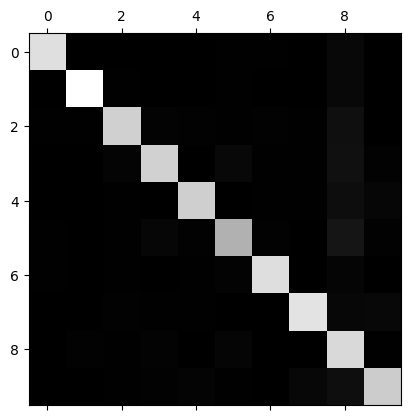

In [143]:
plt.matshow(conf_mx, cmap=plt.cm.gray)
plt.show()


In [144]:
row_sums = conf_mx.sum(axis=1, keepdims=True)
norm_conf_mx = conf_mx / row_sums

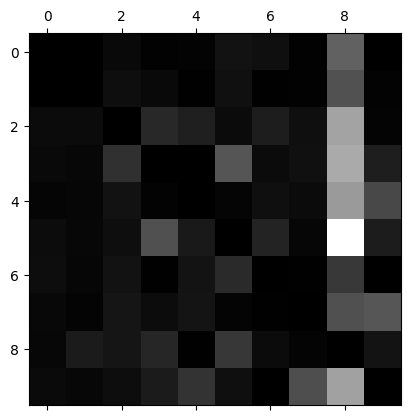

In [145]:
np.fill_diagonal(norm_conf_mx, 0)
plt.matshow(norm_conf_mx, cmap=plt.cm.gray)
plt.show()

In [153]:
noise = np.random.randint(0, 100, (len(x_train), 784))
X_train_mod = x_train + noise
noise = np.random.randint(0, 100, (len(x_test), 784))
X_test_mod = x_test + noise
y_train_mod = x_train
y_test_mod = x_test

In [156]:
from sklearn.neighbors import KNeighborsClassifier
y_train_large = (y_train >= 7)
y_train_odd = (y_train % 2 == 1)
y_multilabel = np.c_[y_train_large, y_train_odd]
knn_clf = KNeighborsClassifier()
knn_clf.fit(x_train, y_multilabel)

KNeighborsClassifier()

In [157]:
knn_clf.predict([some_digit])

array([[False,  True]])

In [158]:
y_train_knn_pred = cross_val_predict(knn_clf, x_train, y_multilabel, cv=3)
f1_score(y_multilabel, y_train_knn_pred, average="macro")

0.976410265560605

In [160]:
noise = np.random.randint(0, 100, (len(x_train), 784))
X_train_mod = x_train + noise
noise = np.random.randint(0, 100, (len(x_test), 784))
X_test_mod = x_test + noise
y_train_mod = x_train
y_test_mod = x_test

In [161]:
knn_clf.fit(X_train_mod, y_train_mod)

KNeighborsClassifier()

In [175]:
import matplotlib.pyplot as plt

def plot_digit(digit_image):
    # Assuming digit_image is a NumPy array representing an image
    plt.imshow(digit_image, cmap='binary', interpolation='nearest')
    plt.axis('off')
    plt.show()


In [180]:
knn_clf.fit(X_train_mod, y_train_mod)
some_index =42
predicted_label = knn_clf.predict([X_test_mod[some_index]])
predicted_image = X_test_mod[some_index]

# Assuming plot_digit is a function that visualizes an image of a digit
mpl.plot_digit(predicted_image)


AttributeError: module 'matplotlib' has no attribute 'plot_digit'

In [179]:
print(type(predicted_image))


<class 'numpy.ndarray'>
